# T47D CDK2/4/6 variant RNA-seq: PCA

Extracted from `t47d_cdk_palbo_deseq2_gsea.ipynb` (PCA section). Run from this folder.

- **Input:** `results/star_salmon/salmon.merged.gene_tpm.tsv` → log2(TPM+1)
- **Method:** top-500 most-variable genes, mean-centered, SVD
- **Style:** colour = genotype, marker = treatment (● DMSO, ▲ Palbo)
- **Output:** `T47D_CDK_palbo_results/figures/PCA.svg` / `PCA.png`

In [15]:
%matplotlib inline
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
# ── Style ────────────────────────────────────────────────────────────────────
plt.rc('font', family='Helvetica')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'   # keep SVG text editable in Illustrator

In [17]:
# ── Paths ────────────────────────────────────────────────────────────────────
BASE = Path.cwd()
EXPR_FILE = BASE / 'salmon.merged.gene_tpm.csv'
FIG_DIR = BASE
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [18]:
# ── Settings ─────────────────────────────────────────────────────────────────
N_TOP = 500                                        # most-variable genes used

# One colour per genotype; treatment shown by marker only.
PCA_COLORS = {
    'ABE_NT': '#8C8C86', 'CBE_NT': '#55554F',       # CBE NT darker so the two controls differ
    'CDK2_S261G': '#5B84B1', 'CDK4_I51V': '#9A82B0',
    'CDK6_G53S': '#D9702E', 'CDK6_R46W': '#7FB49B',
}
treatment_markers = {'veh': 'o', 'palbo': '^'}      # circle = DMSO, triangle = Palbo
treatment_labels = {'veh': 'DMSO', 'palbo': 'Palbo'}


def pretty_label(text):
    """'CDK6_R46W' -> 'CDK6 R46W'; 'ABE_NT' -> 'ABE NT'."""
    return re.sub(r'\b(CDK\d+)_(?=[A-Z]\d+[A-Z])', r'\1 ', str(text)).replace('_NT', ' NT')

In [19]:
# ── Load TPM, build metadata from sample names ───────────────────────────────
expr = pd.read_csv(EXPR_FILE, index_col=0).drop(columns=['gene_name'])
parsed = expr.columns.str.extract(r'^T47D_(?P<genotype>.+)_(?P<treatment>palbo|veh)_\d+$')
metadata = pd.DataFrame({'genotype': parsed['genotype'].values,
                         'treatment': parsed['treatment'].values}, index=expr.columns)
log_expr = np.log2(expr + 1)                        # genes x samples

In [20]:
# ── PCA: top-variable genes, mean-centered, SVD ──────────────────────────────
pca_samples = metadata.index
X = log_expr[pca_samples].T                         # samples x genes
top_genes = X.var(axis=0).sort_values(ascending=False).head(N_TOP).index
Xc = X[top_genes] - X[top_genes].mean(axis=0)
U, S, Vt = np.linalg.svd(Xc.values, full_matrices=False)
scores = U * S
var_pct = (S ** 2) / np.sum(S ** 2) * 100

pca_df = pd.DataFrame({'sample': X.index, 'PC1': scores[:, 0], 'PC2': scores[:, 1]}) \
    .merge(metadata.reset_index().rename(columns={'index': 'sample'}), on='sample')

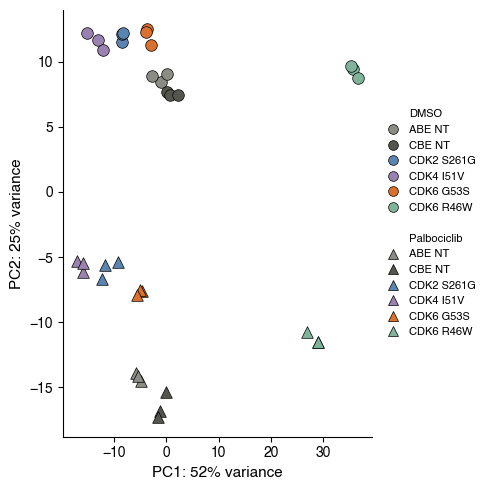

PCA saved to /Users/evelynchen/MIT Dropbox/Evelyn Chen/FSR Lab/Data/RNAseq/20260427_RNAseq. PC1=51.8%  PC2=25.4%


In [21]:
# ── Plot ─────────────────────────────────────────────────────────────────────
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(5, 5))
for (genotype, treatment), grp in pca_df.groupby(['genotype', 'treatment']):
    ax.scatter(grp['PC1'], grp['PC2'],
               color=PCA_COLORS.get(genotype, 'gray'),
               marker=treatment_markers.get(treatment, 'o'),
               s=70, zorder=3, linewidths=0.5, edgecolors='black')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel(f'PC1: {var_pct[0]:.0f}% variance', fontsize=11)
ax.set_ylabel(f'PC2: {var_pct[1]:.0f}% variance', fontsize=11)

# Legend: one column, "DMSO" block on top, "Palbociclib" block below,
# genotypes listed under each header in PCA_COLORS order.
LEGEND_HEADERS = {'veh': 'DMSO', 'palbo': 'Palbociclib'}
shown_genotypes = [g for g in PCA_COLORS if g in set(pca_df['genotype'])]
handles, labels, header_idx = [], [], []
for treatment in ['veh', 'palbo']:
    if handles:                                           # blank spacer between blocks
        handles.append(Line2D([], [], linestyle='none')); labels.append('')
    header_idx.append(len(labels))
    handles.append(Line2D([], [], linestyle='none'))      # invisible handle for the header
    labels.append(LEGEND_HEADERS[treatment])
    for g in shown_genotypes:
        handles.append(Line2D([], [], linestyle='none', marker=treatment_markers[treatment],
                              markersize=7, markerfacecolor=PCA_COLORS[g],
                              markeredgecolor='black', markeredgewidth=0.5))
        labels.append(pretty_label(g))
leg = ax.legend(handles, labels, fontsize=8, frameon=False, ncol=1,
                loc='center left', bbox_to_anchor=(1.0, 0.5), handletextpad=0.4)
for i in header_idx:                                      # bold block headers
    leg.get_texts()[i].set_fontweight('bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'PCA.svg', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'PCA.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"PCA saved to {FIG_DIR}. PC1={var_pct[0]:.1f}%  PC2={var_pct[1]:.1f}%")
